# LAB 08 — KMeans

**Notebook Google Colab | Học máy ứng dụng | Lab 08**

Nội dung theo tài liệu `Lab08_KMeans.pdf`: **phần thực hành theo từng bước + giải 6 bài tập cuối bài**. Các lệnh có chú thích và in kết quả để tiện chụp màn hình.

**Cách sử dụng:** mở tệp `.ipynb` bằng Google Colab → **Runtime → Run all**. Chạy lần lượt từ đầu; dữ liệu CSV được khôi phục tự động trong bước chuẩn bị, không phải tải CSV bằng tay. Ảnh và bảng kết quả được xuất ra thư mục `ket_qua/`. Những kết quả mô hình hoặc thời gian chạy có thể thay đổi theo phiên bản thư viện hoặc máy.

## Chuẩn bị — thư viện, dữ liệu và thư mục kết quả

Bộ dữ liệu lấy trực tiếp từ ZIP người dùng cung cấp, được nhúng vào notebook để mở bằng Colab là chạy được.

In [1]:
# Chuẩn bị dữ liệu gốc đính kèm (tự giải nén, không cần upload riêng).
import base64, io, os, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

_DATA_BASE64 = "UEsDBBQAAAAIADyAPF2FZ7Cc5QcAAGUUAAAXAAAAZGF0YS9oYWlfdmFuZ190cmFuZy5jc3ZVWDmS7cgN9CdibtLTgR2o48iTJVvHF1b+UHvNx0JhSSQS/C/+/Jd+/vPvf/3n77/+gV8ijR/8BWb6gb//gl8P45/8QV8+wX4C3k84tJ/QLwbqD/xa/s0rz4R/+o0yUqddJB8gBY9Zi/fKCGD0Gfw1f2UEQHWMqMQrI/ZszmAdwDg/9D3P31XD9hZiLxMucwJ/GdKD/kF9DmFIhYdv/RD2yCMZyrkqzFZmnd4YUbIx4qDjKr3oBFR8OIdIyhf3TE3fw2aVATXCuYhZXt6MyGOVQjoBgsKX10cdIT5fs8Fa3rFuBsBf/U9P35wxiK6FPdzUA0IVEPmLJ6uUlkD3Yng8F7PghqPRxTHzeeXtK0S8voWD9RNgXN/QJAvxyzKnGhd1k5vSJW5wQsZzkQPTJI7jrIR2LqEOjzdAFWOGsRHhg0pl5uldWqyhIpuXf9ILy2AyDU60YXcp8h2RqCcJ0lfeAeE6Aw0nsEdnVaQLryiXOsJ6wn5FzN/qGg1YbJi3b/CQ1hMkqDMSvghLoPdN2UcxAVFQm+20T+aqemn265eMrJ5kbje5Wr01QNvSJ6Dq6icHDg5sDEocWkyqgSJowU/ScDLH800Qp6yA10MxvthZSTRW4gidzhWqwiNMy+SND7uG6oabhfxtEQT7UkVf76itM0x5Z5qxOLvkfUZxMQedfbK72KGbTFQWpyTdqtGZGDhpNXaGbG/OvCkhkl9qg7hq6Hie8QBOHw6+0nttNLHxXpTVbApIB95QHkO1TGBipf+HKLooght0ZXdIN7NfYyZJNvadlt/4UYeT4Lmqy2BS4JpM/dU9z3QrBmJtl+2aFxrnL4u6idYGCovLulLgbBKMdZZU6+Z4cURDrxJWQNxcJzirxbLfNyDLpDT10FJCtn8zHMLRb5JTFzAvlOk5eOV3WrEFbXrf3ZFhLOnhmwcqS0+GA3SXJYRQa3pyPuRgtn8WhQduBUXUSYr4NrcPRZNsEkBoHjDt+IBpHxq2Sl9JqGfWEQRZ9BFTkE0TFEYKqfJRRGjlifGmBdVAq1MiO9hofcHi6sk/4DJ9XKFlmlfUF3LD/BXYIJCxyVT0SPBZD93XPd3smtAavoXvndfkb3DMvnXOGXeYC+3J7PYWP+id3Wz7HRiuOt5SnF2Ltqsqeg3P7Z7zN6wDmsZ18l2vAPZNjMcbwTPdcMd1QneGgYt/N3kDU3gTYThRUkwmqk5NyqlY3sZk0GMyLI7UmjIy+sNUdmVXyc2uAmzdjqSw+UTpCJIeNjPdQNU2vrh73jNFX2xL5wgpGzkkL5nzP4p/TYNNpnLdWrxRIccplFf6o2lwRm0js1PJ9FmxmvFkcAE+xO3fy8GQYqaC5U8S6hD6lV7Q6OdmTQfoUA+wWnriaT9rbpzy8ZEB71M+6a1XMwLfzYnDCtpoBnjNxOg8Ocs3nSk6pHcqLENrTcHbr/Ka+FAm5uwZ6wfCsOMBMo6yjXHdadCkzCsLcojVNOg+O+qw9GHH6HIJSKPd3qJd3nAJLAuwrFxS3/GtxWHtLKzVMG33Q/mcqyxXV9AyIfNCBS9xqY6aS27o15SZJsp0L8AgJi8w6S7m5qGJpaTKbdMwsOCX/xZ8rgexEhHdSp+a49Ge/iwWYtK8kCjavEjTEWZTLAk/Gd8qUSs9behG8Y9qGb1xmoVbwOekPdHPzf5U/D0MUC3WVpG/ArUIg2+qROE1aS5uokszgnHIVawVl3ms71R01wXSo56YIt7IpxrCpU7oEzk11gpMttOgmTd5Hf4gv3EhBnuNFqqab2lBq4uu3GF2Oqez48rHAFEiqXIfeDOxWTSBgGs41e1AnTZv7CMmEnDHwNKaNPvjO9TTq9Xncn+vNOmd2glg8UHyTeNUFb0v1co1aSi8Fja7KzrI1rcpPq9zs3FL/dGOwFKZ2EL73RqAvVGV7p7kE/YMco7bLmKyFLHdIiliRhtdbnM0dAowbmuB4sfUTHY5CeCxctm3Jc5UT9ftPV/Q1oYOYKUod+r1oFMkJ8lUmwCDPoH8tBXmG8nZe0ULo6T+e6UEWC1ctxMkqxZAoYTYUEh3aHLoMWQuZz2x3qdsGVYc+vUf7aq07Yc1nivJtzgRFsYSltPmiVgdKY+x1YUmzCTD2y99Rk269828RGMZ0RvJKTOapuy6LfV7BZPzZcVkUVwrC/ArhPfCKUanQ1bvtEybTtFhXbFjvyxKL2zyjTBZomW7LwLODU8wO4aPGRvg8Cm/HZ/vSphKv7LtrRu2tYfQv31SCzE1sZZAkn0q6BzNqzGy31aDvlPZPqqjl6GNoNWMmR7jzy7iI8eKzmvVyTeQ+RYn0dkEr4tzgvcqRX6aY9khR8H1cSmUIm/ZfKeRYWK2D5MlDlvc/b/uxj98wd3jmQRYPc/dtXjztvVcrjd80c03HsK3PUoUvQZm1+4DHLWvwqcWZGhK7AQS9JytBC/P9peZlDizlFfrvWlR+b7PeJ8AjGuNyWLW5NvKqcvFeJH0xgp/RPlM8yxa7PTKsDs+315Bnj3ev2q+2oTro8C3gneH1y4YfxDau5h+q/JUT3tWzpzBXlXS2CKJaAePvMMw1ZZUyD3V5TJLBdCNvFywe5NX/uQ1tBADwuPh/qzQC+/nMPX3MJZTVTTSXiU+BpAdt6NuSj7MVzdXW/aKGRJJUUs92aIzfMi+z1KzkYFemD0f/mm9uFCgTjC9kRz/A1BLAwQUAAAACABOhzxdU9fuDiAEAACyCQAAEwAAAGRhdGEva2hhY2hfaGFuZy5jc3ZNVsluXDkQuwfInwgNVWn/GiOYBLAPmcnB/v9wUdtzaQhCvVpIFtXvH/+9lffXj5d/X3/8KT/ffv1++ef17eX97dfH929tlP5oZSWOs7R8rLL392+98dxKNJxXifqoJQbOu6xHL7F1nfORZR+HHISMwDkQ+TilH6WMhTQd9xkl92OWM54xjs/Be/wwfrPsKdvxLXDPdrKibOg62EHq2BDR+GVFxlFi4jwQ3dD3Rnhnl7VsFGIIrhuO+9Y8D2RauM7S6k2Ovg7aPf2JRi+b514mIoJfLkQAgFTq6CwzVB4Js2QXRiifZaDmqMTO8RpilkW8JmfbhnQRo08sBDv76vgqWBUUtEp8h1Lm4bdR1lT6JDDhSbMTDWO3CF0oPcKRyzMB9iZgshUe51YlIAA6USk3w88X6kcIAHWQfcrqagawdxPJGVCpo+GRbrJPxU/MtxEyNF+ajcV+e1lXeMcCu1DH0TWSL6kKCaGM5ukGcJ9owiLhoKuZU+FrIoOkjiEgB1UynZ3y3Qw5VxndeBFr4j6C6knfTwHDomyGNO2UNNDkEMMUGJtsXRTgnt9LJ0EVSBHtgrqNO6VPZIgYZaD1qCzrVcl1a1V1P9ExlQI+NrKQbNCUXCZqGdHAfav5JhEYMgw1WbSqGa7Y2l69SS0T7GMmRU1QtRxShZIIH2om2Ys3PqcEzwaAXlKp0zuG8CXg45hVCgXqZOtEzFWPvKULAfS7LPh5BTHQCIUqvKTkbuXLQao0QMLy7ltDDpGkdV9ltOcZUk5PQeLnMRvj1mzbWyBvE5Op6YYYmN4IrOxdGhAPIhG3JeWBiG3lIXuXnZFTTje6jIhJ1hC8nchVo1j5pVXCfGm67HFofSaRQ1xTeNKHNFKTVYRBh8us0ql2kHz3RDZYlQSQB5njDgKjQSlUL3693pDY1mvV1rQdCfyTFPraoE820dml7tQekTcZT9rjKnmbwoqyPOdrM9OI7+sGXHW6IDtsaevXCsoCpvYIHqSXRQqhxyJuCImg8cyQ/CQWOh8+1RqxmWzyJn5JQyTmNE1c8x2iNYwhu0+/GRxiDh33fQQ+3bB6EwitCGqXt/SeqRVLMTg/4U++BgQgjBHfUMa0NKJHxNECr3k9F9dee2xkTRxy5NG9QtPvLQSy5RyYTaLoRii4Ihyfq0hGW5UqpX8qEfJTv932qarp1qk5luKr2TnG1Prlvk3C7YPvraxm+JWzpzWuxdpPTwuNZ3k1i75riyWBfZ/NKtVx/6Yf9nVF8mkFhLQJI4JBV+hUsZ9EPsNPL+BTNustE4rO4z8N6ooeciwo7COL22f53yD81KjVuFKkFsLK1UMtWz4SNHOPeV18yYn1xnMcLi43Z5rcyLus+fzz4/0LNkOPYkxjv/Zl/WsxWPpfczFPyfF/Gw1F/QVQSwECFAAUAAAACAA8gDxdhWewnOUHAABlFAAAFwAAAAAAAAAAAAAAtoEAAAAAZGF0YS9oYWlfdmFuZ190cmFuZy5jc3ZQSwECFAAUAAAACABOhzxdU9fuDiAEAACyCQAAEwAAAAAAAAAAAAAAtoEaCAAAZGF0YS9raGFjaF9oYW5nLmNzdlBLBQYAAAAAAgACAIYAAABrDAAAAAA="
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_DATA_BASE64))) as z:
    for item in z.infolist():
        target = Path(item.filename)
        if target.is_absolute() or '..' in target.parts:
            raise ValueError('Duong dan ZIP khong an toan')
        z.extract(item, '.')
Path('ket_qua').mkdir(exist_ok=True)
print('Da nap:', sorted(str(p) for p in Path('data').glob('*')))
print('Phien ban sklearn:')
import sklearn
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)  # Giảm độ trễ BLAS khi huấn luyện trên CPU Colab
print(sklearn.__version__)

Da nap: ['data/hai_vang_trang.csv', 'data/khach_hang.csv']
Phien ban sklearn:
1.6.1


## Phần I — Thực hành 5 bước theo tài liệu

### Bước 1 (mục 2): Tự lập trình K-Means cho 7 điểm A–G

Vong 1: tam=[[1.0, 1.0], [1.5, 2.0]]
  Cum 1 : ['A']
  Cum 2 : ['B', 'C', 'D', 'E', 'F', 'G']
Vong 2: tam=[[1.0, 1.0], [3.5, 4.58]]
  Cum 1 : ['A', 'B']
  Cum 2 : ['C', 'D', 'E', 'F', 'G']
Vong 3: tam=[[1.25, 1.5], [3.9, 5.1]]
  Cum 1 : ['A', 'B']
  Cum 2 : ['C', 'D', 'E', 'F', 'G']
Dung vi tam khong doi.
Inertia tu tinh: 8.525 | Sklearn: 8.525


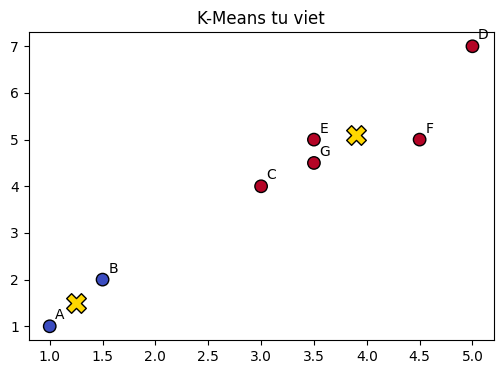

In [2]:
from sklearn.cluster import KMeans,DBSCAN
from sklearn.metrics import silhouette_score,adjusted_rand_score
from sklearn.preprocessing import StandardScaler
P=np.array([[1.,1.],[1.5,2.],[3.,4.],[5.,7.],[3.5,5.],[4.5,5.],[3.5,4.5]])
names=list('ABCDEFG')
def kmeans_numpy(X,centers,max_iter=10):
    centers=np.asarray(centers,dtype=float).copy()
    for step in range(1,max_iter+1):
        distance=np.linalg.norm(X[:,None,:]-centers[None,:,:],axis=2)
        labels=distance.argmin(axis=1)
        print(f'Vong {step}: tam={np.round(centers,2).tolist()}')
        for k in range(len(centers)):
            print('  Cum',k+1,':',[names[i] for i in range(len(X)) if labels[i]==k])
        new=np.array([X[labels==k].mean(axis=0) if np.any(labels==k) else centers[k] for k in range(len(centers))])
        if np.allclose(new,centers):
            print('Dung vi tam khong doi.');break
        centers=new
    return centers,labels
centers,labels=kmeans_numpy(P,P[[0,1]])
self_inertia=np.sum((P-centers[labels])**2)
km7=KMeans(n_clusters=2,init=P[[0,1]],n_init=1).fit(P)
print('Inertia tu tinh:',self_inertia,'| Sklearn:',km7.inertia_)
plt.figure(figsize=(6,4));plt.scatter(P[:,0],P[:,1],c=labels,cmap='coolwarm',s=80,edgecolor='k');plt.scatter(centers[:,0],centers[:,1],marker='X',s=200,c='gold',edgecolor='k')
for p,n in zip(P,names):plt.annotate(n,p,xytext=(4,5),textcoords='offset points')
plt.title('K-Means tu viet');plt.savefig('ket_qua/lab08_buoc1_7diem.png',dpi=150,bbox_inches='tight');plt.show()

### Bước 2 (mục 3): Phân khúc khách hàng và đưa khách mới vào cụm

Kich thuoc: (210, 3)


,tuoi,thu_nhap,diem_chi_tieu
count,210.00,210.00,210.00
mean,37.62,18.52,49.90
std,10.29,9.78,26.82
min,18.00,3.00,7.00
25%,30.00,8.83,22.00
50%,39.00,17.40,49.00
75%,46.00,28.58,77.00
max,62.00,35.50,99.00


Tam cum ve don vi goc:


,thu_nhap,diem_chi_tieu,so_khach,tuoi_tb
0,7.48,80.20,35,24.94
1,30.13,19.97,35,42.86
2,17.39,49.30,60,40.45
3,8.04,18.85,40,44.88
4,30.21,81.53,40,32.62


Inertia: 23.01674878194891
Cum cho khach moi: [4, 0]


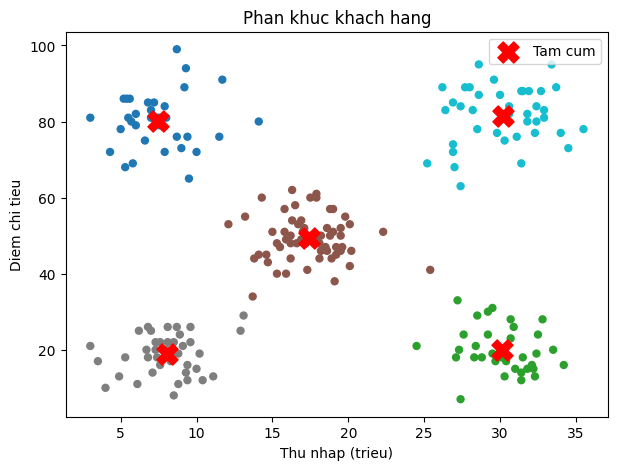

In [3]:
customers=pd.read_csv('data/khach_hang.csv')
print('Kich thuoc:',customers.shape);display(customers.describe().round(2))
features2=['thu_nhap','diem_chi_tieu'];scaler2=StandardScaler().fit(customers[features2])
Xs2=scaler2.transform(customers[features2]);km5=KMeans(n_clusters=5,n_init=10,random_state=0).fit(Xs2)
customers['cum']=km5.labels_
centers_original=pd.DataFrame(scaler2.inverse_transform(km5.cluster_centers_),columns=features2)
centers_original['so_khach']=np.bincount(km5.labels_)
centers_original['tuoi_tb']=customers.groupby('cum')['tuoi'].mean().to_numpy()
print('Tam cum ve don vi goc:');display(centers_original.round(2))
print('Inertia:',km5.inertia_)
new=pd.DataFrame({'thu_nhap':[29.,9.],'diem_chi_tieu':[85,75]})
print('Cum cho khach moi:',km5.predict(scaler2.transform(new)).tolist())
plt.figure(figsize=(7,5));plt.scatter(customers.thu_nhap,customers.diem_chi_tieu,c=km5.labels_,s=25,cmap='tab10')
plt.scatter(centers_original.thu_nhap,centers_original.diem_chi_tieu,marker='X',c='red',s=230,label='Tam cum')
plt.xlabel('Thu nhap (trieu)');plt.ylabel('Diem chi tieu');plt.legend();plt.title('Phan khuc khach hang')
plt.savefig('ket_qua/lab08_buoc2_khach_hang.png',dpi=150,bbox_inches='tight');plt.show()

### Bước 3 (mục 4): Chọn K bằng khuỷu tay và silhouette

,K,Inertia,Silhouette
0,1,420.0000,NaN
1,2,250.3985,0.4300
2,3,152.5400,0.5217
3,4,73.7574,0.6256
4,5,23.0167,0.7227
5,6,20.8739,0.6508
6,7,19.0119,0.5413
7,8,17.4235,0.4538
8,9,15.8928,0.4713
9,10,14.4467,0.4254


K tot nhat bang silhouette: 5


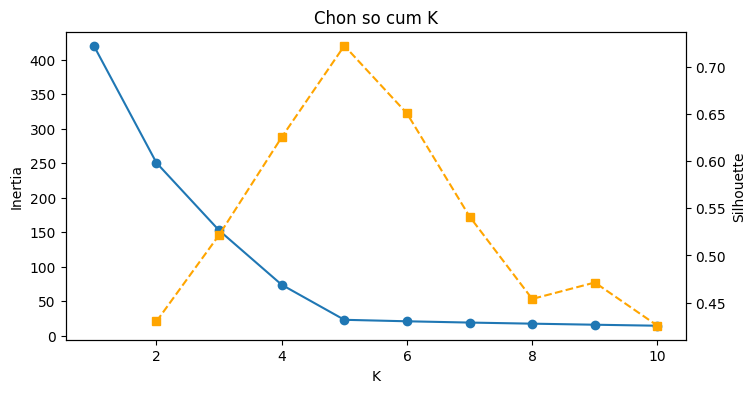

In [4]:
k_rows=[]
for k in range(1,11):
    km=KMeans(n_clusters=k,n_init=10,random_state=0).fit(Xs2)
    sil=np.nan if k==1 else silhouette_score(Xs2,km.labels_)
    k_rows.append([k,km.inertia_,sil])
k_table=pd.DataFrame(k_rows,columns=['K','Inertia','Silhouette'])
display(k_table.round(4))
print('K tot nhat bang silhouette:',int(k_table.loc[k_table.Silhouette.idxmax(),'K']))
fig,ax1=plt.subplots(figsize=(8,4));ax1.plot(k_table.K,k_table.Inertia,'o-',label='Inertia');ax1.set_xlabel('K');ax1.set_ylabel('Inertia')
ax2=ax1.twinx();ax2.plot(k_table.K,k_table.Silhouette,'s--',c='orange',label='Silhouette');ax2.set_ylabel('Silhouette')
plt.title('Chon so cum K');plt.savefig('ket_qua/lab08_buoc3_chon_k.png',dpi=150,bbox_inches='tight');plt.show()

### Bước 4 (mục 5): Ba bẫy: thiếu chuẩn hóa, khởi tạo ngẫu nhiên, cụm không tròn

In [5]:
X_thousand=customers[features2].copy();X_thousand['thu_nhap']*=1000
bad_scale=KMeans(n_clusters=5,n_init=10,random_state=0).fit(X_thousand)
cent_bad=bad_scale.cluster_centers_.copy();cent_bad[:,0]/=1000
print('Bay 1: tam cum khong chuan hoa:');print(np.round(cent_bad[np.argsort(cent_bad[:,0])],2))
seeds=[KMeans(n_clusters=5,init='random',n_init=1,random_state=i).fit(Xs2).inertia_ for i in range(20)]
print('Bay 2: inertia cua 20 lan khoi tao:',np.round(sorted(seeds),1))
moons=pd.read_csv('data/hai_vang_trang.csv')
Xmoon=moons[['x1','x2']].to_numpy();true_moon=moons.nhan.to_numpy()
labels_m=KMeans(n_clusters=2,n_init=10,random_state=0).fit_predict(Xmoon)
match=max(np.mean(labels_m==true_moon),np.mean(1-labels_m==true_moon))
print('Bay 3: phan cum hai vang trang chi khop nhan that:',round(match,4))

Bay 1: tam cum khong chuan hoa:
[[ 6.09 52.5 ]
 [ 9.56 41.95]
 [17.36 49.81]
 [27.78 52.94]
 [31.9  52.42]]
Bay 2: inertia cua 20 lan khoi tao: [ 23.   23.   23.   23.   23.   23.   23.   23.   23.   23.   72.4  73.6
  73.7  73.7  84.   84.2  84.2 116.6 117.4 118.2]
Bay 3: phan cum hai vang trang chi khop nhan that: 0.75


### Bước 5 (mục 6): Nén màu ảnh bằng K-Means

Kich thuoc anh: (427, 640, 3) | so mau goc: 96615
 4 mau: 2 bit/pixel, nen ly thuyet 12.0 lan, sai lech anh sang trung binh 17.411
16 mau: 4 bit/pixel, nen ly thuyet 6.0 lan, sai lech anh sang trung binh 7.975
64 mau: 6 bit/pixel, nen ly thuyet 4.0 lan, sai lech anh sang trung binh 4.539


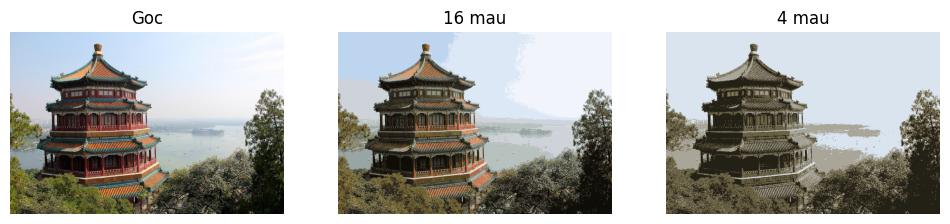

In [6]:
from sklearn.datasets import load_sample_image
image=load_sample_image('china.jpg')
height,width,_=image.shape
pixels=image.reshape(-1,3)/255.
rng=np.random.default_rng(0)
sample=pixels[rng.choice(len(pixels),5000,replace=False)]
print('Kich thuoc anh:',image.shape,'| so mau goc:',len(np.unique(image.reshape(-1,3),axis=0)))
compressed_images={}
for k in [4,16,64]:
    km=KMeans(n_clusters=k,n_init=4,random_state=0).fit(sample)
    pred=km.cluster_centers_[km.predict(pixels)].reshape(height,width,3)
    compressed_images[k]=np.clip(pred,0,1)
    err=np.abs(pred.reshape(-1,3)-pixels).mean()*255
    print(f'{k:2d} mau: {np.ceil(np.log2(k)):.0f} bit/pixel, nen ly thuyet {24/np.ceil(np.log2(k)):.1f} lan, sai lech anh sang trung binh {err:.3f}')
fig,ax=plt.subplots(1,3,figsize=(12,4))
for a,(label,img) in zip(ax,[('Goc',image),('16 mau',compressed_images[16]),('4 mau',compressed_images[4])]):
    a.imshow(img);a.set_title(label);a.axis('off')
plt.savefig('ket_qua/lab08_buoc5_nen_anh.png',dpi=150,bbox_inches='tight');plt.show()

## Phần II — Giải 6 bài tập Lab 08

### Bài tập 1 — Tự viết silhouette cho từng khách, chỉ dùng numpy

Tu tinh silhouette TB: 0.7227055107668372 | Sklearn: 0.7227055107668373
Khach s thap nhat: 113 | s= 0.0286 | thu nhap, diem chi tieu= {'thu_nhap': 25.4, 'diem_chi_tieu': 41.0}


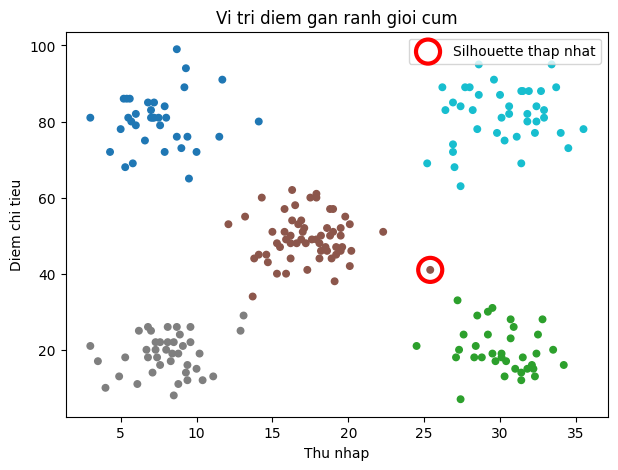

Nhan xet: s thap thuong o giua cac cum, kho phan biet gan cum minh hay cum ben canh.


In [7]:
def silhouette_mot_diem(X,nhan,i):
    X=np.asarray(X,float);nhan=np.asarray(nhan)
    group=nhan[i]
    same=np.flatnonzero(nhan==group)
    if len(same)<=1:return 0.0,0.0,0.0
    same=same[same!=i]
    d=np.linalg.norm(X-X[i],axis=1)
    a=d[same].mean()
    b=min(d[nhan==k].mean() for k in np.unique(nhan) if k!=group)
    s=(b-a)/max(a,b) if max(a,b)>0 else 0.0
    return float(a),float(b),float(s)
all_s=np.array([silhouette_mot_diem(Xs2,km5.labels_,i)[2] for i in range(len(Xs2))])
minimum=int(all_s.argmin())
print('Tu tinh silhouette TB:',all_s.mean(),'| Sklearn:',silhouette_score(Xs2,km5.labels_))
print('Khach s thap nhat:',minimum,'| s=',round(all_s[minimum],4),'| thu nhap, diem chi tieu=',customers.loc[minimum,features2].to_dict())
plt.figure(figsize=(7,5));plt.scatter(customers.thu_nhap,customers.diem_chi_tieu,c=km5.labels_,cmap='tab10',s=22)
plt.scatter(customers.loc[minimum,'thu_nhap'],customers.loc[minimum,'diem_chi_tieu'],facecolors='none',edgecolors='red',s=300,linewidths=3,label='Silhouette thap nhat')
plt.xlabel('Thu nhap');plt.ylabel('Diem chi tieu');plt.legend();plt.title('Vi tri diem gan ranh gioi cum')
plt.savefig('ket_qua/lab08_bai1_silhouette_min.png',dpi=150,bbox_inches='tight');plt.show()
print('Nhan xet: s thap thuong o giua cac cum, kho phan biet gan cum minh hay cum ben canh.')

### Bài tập 2 — Thêm cột tuổi, chọn lại K bằng silhouette

In [8]:
features3=['tuoi','thu_nhap','diem_chi_tieu']
scaler3=StandardScaler().fit(customers[features3]);Xs3=scaler3.transform(customers[features3])
three_results=[]
for k in range(2,11):
    mm=KMeans(n_clusters=k,n_init=10,random_state=0).fit(Xs3)
    three_results.append([k,silhouette_score(Xs3,mm.labels_)])
three=pd.DataFrame(three_results,columns=['K','Silhouette']);display(three.round(4))
best_k=int(three.loc[three.Silhouette.idxmax(),'K'])
km3=KMeans(n_clusters=best_k,n_init=10,random_state=0).fit(Xs3)
ct3=pd.DataFrame(scaler3.inverse_transform(km3.cluster_centers_),columns=features3)
print('K toi uu theo 3 cot:',best_k,'| So voi K=5 o muc 3')
display(ct3.round(2))
print('Nhan xet: them tuoi co the tach/nhap nhom; so thu tu cum la tuy y, so sanh bang toa do tam chu khong theo so cum.')

,K,Silhouette
0,2,0.3730
1,3,0.4220
2,4,0.4558
3,5,0.4808
4,6,0.4760
5,7,0.4627
6,8,0.4596
7,9,0.4622
8,10,0.4573


K toi uu theo 3 cot: 5 | So voi K=5 o muc 3


,tuoi,thu_nhap,diem_chi_tieu
0,44.88,8.04,18.85
1,25.13,8.48,77.56
2,42.86,30.13,19.97
3,32.08,30.28,82.00
4,41.65,17.58,49.18


Nhan xet: them tuoi co the tach/nhap nhom; so thu tu cum la tuy y, so sanh bang toa do tam chu khong theo so cum.


### Bài tập 3 — So sánh random và k-means++ qua 50 lần khởi tạo

In [9]:
rows=[]
for init in ['random','k-means++']:
    scores=[KMeans(n_clusters=5,init=init,n_init=1,random_state=seed).fit(Xs2).inertia_ for seed in range(50)]
    count=sum(np.isclose(s,23.0,atol=.15) for s in scores)
    rows.append([init,count,np.mean(scores),np.min(scores),np.max(scores)])
df_init=pd.DataFrame(rows,columns=['Init','So lan inertia xap xi 23.0','Inertia TB','Tot nhat','Te nhat']);display(df_init.round(3))
print('Ket luan: khoi tao co xac suat dat inertia tot cao hon va do bien thien thap hon la dang tin hon.')

,Init,So lan inertia xap xi 23.0,Inertia TB,Tot nhat,Te nhat
0,random,30,53.291,23.017,204.046
1,k-means++,50,23.017,23.017,23.017


Ket luan: khoi tao co xac suat dat inertia tot cao hon va do bien thien thap hon la dang tin hon.


### Bài tập 4 — Lưu ảnh 16 màu và so kích thước PNG

**Ảnh tự chọn:** có thể upload tệp tên `anh_cua_em.png` vào Colab trước khi chạy ô này; nếu chưa có, ô vẫn chạy và bỏ qua phần tùy chọn.

In [10]:
from pathlib import Path
original_path=Path('ket_qua/anh_goc.png');compressed_path=Path('ket_qua/anh_16_mau.png')
plt.imsave(original_path,image)
anh_moi=compressed_images[16]
assert anh_moi.shape==(427,640,3)
plt.imsave(compressed_path,anh_moi)
size0=original_path.stat().st_size;size16=compressed_path.stat().st_size
print('Anh goc:',size0,'bytes | 16 mau:',size16,'bytes | Ti so file PNG:',round(size0/size16,3))
print('Luu y: dung luong PNG phu thuoc nen khong mat mat, khac ti le bit/pixel 6x ly thuyet.')
def nen_anh_rieng(filename='anh_cua_em.png',k=16):
    src=np.asarray(plt.imread(filename))
    if src.shape[-1]==4:src=src[...,:3]  # bỏ alpha
    if src.max()>1:src=src/255.
    h,w,_=src.shape;pix=src.reshape(-1,3)
    rand=np.random.default_rng(0)
    train=pix[rand.choice(len(pix),min(5000,len(pix)),replace=False)]
    mo=KMeans(n_clusters=k,n_init=4,random_state=0).fit(train)
    out=np.clip(mo.cluster_centers_[mo.predict(pix)].reshape(h,w,3),0,1)
    plt.imsave('ket_qua/anh_cua_em_16_mau.png',out)
    return out
if Path('anh_cua_em.png').exists():
    custom=nen_anh_rieng();print('Da luu anh rieng 16 mau:',custom.shape)
else:
    print('Chua co anh_cua_em.png -> bo qua phan anh rieng (tuy chon).')

Anh goc: 551315 bytes | 16 mau: 155488 bytes | Ti so file PNG: 3.546
Luu y: dung luong PNG phu thuoc nen khong mat mat, khac ti le bit/pixel 6x ly thuyet.
Chua co anh_cua_em.png -> bo qua phan anh rieng (tuy chon).


### Bài tập 5 — DBSCAN và K-Means trên dữ liệu hai vầng trăng

In [11]:
db_rows=[]
for e in [.2,.3,.4]:
    db=DBSCAN(eps=e,min_samples=5).fit(Xmoon)
    labels_db=db.labels_
    num_clusters=len(set(labels_db))-(1 if -1 in labels_db else 0)
    noise=int(np.sum(labels_db==-1))
    ari=adjusted_rand_score(true_moon,labels_db)
    db_rows.append([e,num_clusters,noise,ari])
display(pd.DataFrame(db_rows,columns=['eps','So cum','So diem nhieu','ARI so voi nhan that']).round(4))
print('ARI KMeans:',round(adjusted_rand_score(true_moon,labels_m),4))
print('Nhan xet: eps qua nho -> nhieu diem nhieu; qua lon -> 2 vang trang co the nhap mot; ARI cao hon KMeans chung to tach tot hon.')

,eps,So cum,So diem nhieu,ARI so voi nhan that
0,0.2,1,40,-0.0014
1,0.3,1,10,0.0012
2,0.4,1,3,-0.0001


ARI KMeans: 0.2475
Nhan xet: eps qua nho -> nhieu diem nhieu; qua lon -> 2 vang trang co the nhap mot; ARI cao hon KMeans chung to tach tot hon.


### Bài tập 6 — K-Means trên chữ số viết tay và bảng chéo

In [12]:
from sklearn.datasets import load_digits
Xd,yd=load_digits(return_X_y=True)
labels_digits=KMeans(n_clusters=10,n_init=10,random_state=0).fit_predict(Xd)
cross=pd.crosstab(pd.Series(yd,name='Nhan that'),pd.Series(labels_digits,name='Cum'))
display(cross)
print('Moi chu so -> cum co nhieu mau nhat:')
for digit,row in cross.iterrows():
    k=int(row.idxmax());count=int(row.max());total=int(row.sum())
    print(f'  so {digit} -> cum {k}: {count}/{total} = {count/total:.1%}')
print('Moi cum -> cac chu so noi troi:')
for cluster in cross.columns:
    top=cross[cluster].sort_values(ascending=False).head(3)
    print('  cum',cluster,':',top.to_dict())
print('Nhan xet: mot cum co nhieu so khac nhau la bang chung cac dang chu viet gan nhau trong khong gian diem anh.')

Cum,0,1,2,3,4,5,6,7,8,9
Nhan that,,,,,,,,,,
0,176,0,0,0,0,0,2,0,0,0
1,0,100,0,54,1,2,0,1,0,24
2,1,8,3,2,13,0,0,0,2,148
3,0,7,7,0,154,0,0,2,13,0
4,0,2,11,3,0,0,165,0,0,0
5,0,0,0,0,2,1,2,136,41,0
6,1,3,0,0,0,177,0,0,0,0
7,0,2,174,2,0,0,0,1,0,0
8,0,100,5,6,2,2,0,4,52,3


Moi chu so -> cum co nhieu mau nhat:
  so 0 -> cum 0: 176/178 = 98.9%
  so 1 -> cum 1: 100/182 = 54.9%
  so 2 -> cum 9: 148/177 = 83.6%
  so 3 -> cum 4: 154/183 = 84.2%
  so 4 -> cum 6: 165/181 = 91.2%
  so 5 -> cum 7: 136/182 = 74.7%
  so 6 -> cum 5: 177/181 = 97.8%
  so 7 -> cum 2: 174/179 = 97.2%
  so 8 -> cum 1: 100/174 = 57.5%
  so 9 -> cum 8: 139/180 = 77.2%
Moi cum -> cac chu so noi troi:
  cum 0 : {0: 176, 2: 1, 6: 1}
  cum 1 : {1: 100, 8: 100, 2: 8}
  cum 2 : {7: 174, 4: 11, 9: 8}
  cum 3 : {1: 54, 9: 20, 8: 6}
  cum 4 : {3: 154, 2: 13, 9: 6}
  cum 5 : {6: 177, 1: 2, 8: 2}
  cum 6 : {4: 165, 0: 2, 5: 2}
  cum 7 : {5: 136, 9: 6, 8: 4}
  cum 8 : {9: 139, 8: 52, 5: 41}
  cum 9 : {2: 148, 1: 24, 8: 3}
Nhan xet: mot cum co nhieu so khac nhau la bang chung cac dang chu viet gan nhau trong khong gian diem anh.
